In [1]:
import os
import sys
from pathlib import Path

current_dir = Path.cwd()

possible_roots = [current_dir, current_dir.parent]

PROJECT_ROOT = next(
    (
        p for p in possible_roots
        if (p / "src" / "data" / "dataset.py").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found.")

sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from src.data.dataset import get_dataset_splits

print("TensorFlow:", tf.__version__)
print("Project:", PROJECT_ROOT)


TensorFlow: 2.15.0
Project: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow


Model configuration

In [2]:
IMAGE_SIZE = 224
GRID_SIZE = 7
NUM_CLASSES = 6
NUM_ANCHORS = 5

INPUT_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Input shape:", INPUT_SHAPE)
print("Number of classes:", NUM_CLASSES)
print("Grid size:", GRID_SIZE)
print("Number of anchors:", NUM_ANCHORS)

Input shape: (224, 224, 3)
Number of classes: 6
Grid size: 7
Number of anchors: 5


Load the dataset

In [3]:
train, val, test = get_dataset_splits("data/NEU-DET")

print("Training images:", len(train))
print("Validation images:", len(val))
print("Testing images:", len(test))

print("Sample keys:", train[0].keys())

Training images: 1151
Validation images: 288
Testing images: 360
Sample keys: dict_keys(['image', 'boxes', 'labels', 'stratify'])


Calculate bounding-box dimensions

In [4]:
box_dimensions = []

for sample in train:

    for box in sample["boxes"]:

        xmin, ymin, xmax, ymax = box

        width = xmax - xmin
        height = ymax - ymin

        if width > 0 and height > 0:
            box_dimensions.append([width, height])

box_dimensions = np.asarray(
    box_dimensions,
    dtype=np.float32
)

print("Total training boxes:", len(box_dimensions))
print("Box dimensions shape:", box_dimensions.shape)

print("Minimum width:", box_dimensions[:, 0].min())
print("Maximum width:", box_dimensions[:, 0].max())
print("Minimum height:", box_dimensions[:, 1].min())
print("Maximum height:", box_dimensions[:, 1].max())

Total training boxes: 2676
Box dimensions shape: (2676, 2)
Minimum width: 0.03999996
Maximum width: 0.995
Minimum height: 0.045000017
Maximum height: 0.995


Generate anchor boxes

In [5]:
kmeans = KMeans(
    n_clusters=NUM_ANCHORS,
    random_state=42,
    n_init=10
)

kmeans.fit(box_dimensions)

ANCHORS = kmeans.cluster_centers_

# Sort anchors by area
ANCHORS = ANCHORS[
    np.argsort(ANCHORS[:, 0] * ANCHORS[:, 1])
]

print("Generated anchors:")
print(ANCHORS)

anchor_df = pd.DataFrame(
    ANCHORS,
    columns=["width", "height"]
)

anchor_df["area"] = (
    anchor_df["width"] * anchor_df["height"]
)

display(anchor_df)

Generated anchors:
[[0.18283209 0.24619974]
 [0.28540698 0.51598006]
 [0.21671906 0.910609  ]
 [0.6913246  0.32715988]
 [0.81677145 0.9229429 ]]


,width,height,area
0,0.182832,0.246200,0.045013
1,0.285407,0.515980,0.147264
2,0.216719,0.910609,0.197346
3,0.691325,0.327160,0.226174
4,0.816771,0.922943,0.753833


Visualize anchor sizes

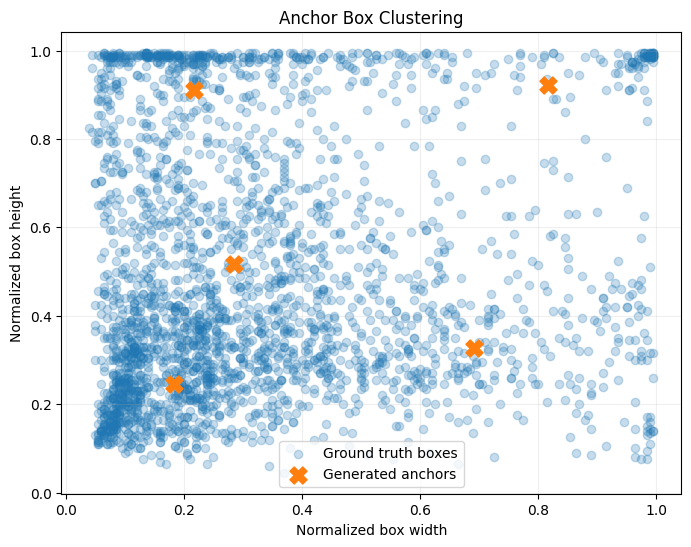

In [6]:
plt.figure(figsize=(8, 6))

plt.scatter(
    box_dimensions[:, 0],
    box_dimensions[:, 1],
    alpha=0.25,
    label="Ground truth boxes"
)

plt.scatter(
    ANCHORS[:, 0],
    ANCHORS[:, 1],
    marker="X",
    s=150,
    label="Generated anchors"
)

plt.xlabel("Normalized box width")
plt.ylabel("Normalized box height")
plt.title("Anchor Box Clustering")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Build MobileNetV2 backbone

In [7]:
def build_backbone(input_shape=INPUT_SHAPE):

    backbone = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights="imagenet"
    )

    backbone.trainable = False

    return backbone


backbone = build_backbone()

print("Backbone output shape:", backbone.output_shape)
print("Backbone trainable:", backbone.trainable)



Backbone output shape: (None, 7, 7, 1280)
Backbone trainable: False


Build object detection model

In [8]:
def build_detector():

    inputs = tf.keras.Input(
        shape=INPUT_SHAPE,
        name="input_image"
    )

    backbone = tf.keras.applications.MobileNetV2(
        input_shape=INPUT_SHAPE,
        include_top=False,
        weights="imagenet"
    )

    backbone.trainable = False

    features = backbone(
        inputs,
        training=False
    )

    x = tf.keras.layers.Conv2D(
        256,
        kernel_size=3,
        padding="same",
        activation="swish",
        name="detection_conv_1"
    )(features)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.Conv2D(
        128,
        kernel_size=3,
        padding="same",
        activation="swish",
        name="detection_conv_2"
    )(x)

    output_channels = NUM_ANCHORS * (5 + NUM_CLASSES)

    x = tf.keras.layers.Conv2D(
        output_channels,
        kernel_size=1,
        padding="same",
        name="prediction_head"
    )(x)

    outputs = tf.keras.layers.Reshape(
        (
            GRID_SIZE,
            GRID_SIZE,
            NUM_ANCHORS,
            5 + NUM_CLASSES
        ),
        name="detection_predictions"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="MobileNetV2_Industrial_Defect_Detector"
    )

    return model


model = build_detector()

model.summary()

Model: "MobileNetV2_Industrial_Defect_Detector"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_image (InputLayer)    [(None, 224, 224, 3)]     0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 detection_conv_1 (Conv2D)   (None, 7, 7, 256)         2949376   
                                                                 
 batch_normalization (Batch  (None, 7, 7, 256)         1024      
 Normalization)                                                  
                                                                 
 detection_conv_2 (Conv2D)   (None, 7, 7, 128)         295040    
                                                                 
 prediction_head (Conv2D)   

Verify model output

In [9]:
dummy_input = tf.zeros(
    shape=(1, IMAGE_SIZE, IMAGE_SIZE, 3),
    dtype=tf.float32
)

predictions = model(dummy_input, training=False)

print("Input shape:", dummy_input.shape)
print("Prediction shape:", predictions.shape)
print("Prediction dtype:", predictions.dtype)

assert predictions.shape == (
    1, GRID_SIZE, GRID_SIZE, NUM_ANCHORS, 11
)

print("Model architecture verification: PASSED")

Input shape: (1, 224, 224, 3)
Prediction shape: (1, 7, 7, 5, 11)
Prediction dtype: <dtype: 'float32'>
Model architecture verification: PASSED


Model parameters

In [10]:
total_params = model.count_params()

trainable_params = sum(
    np.prod(weight.shape)
    for weight in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(weight.shape)
    for weight in model.non_trainable_weights
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Total parameters: 5510519
Trainable parameters: 3252023
Non-trainable parameters: 2258496


Save initial architecture

In [11]:
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(exist_ok=True)

model_path = models_dir / "detector_initial.keras"

model.save(model_path)

print("Initial model saved:", model_path)

Initial model saved: d:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\models\detector_initial.keras
